# Inteligencia Artificial II — Proyecto, Entrega 2
## Clasificación semi-supervisada de enfermedades en hojas de tomate con PlantVillage

**Grupo:** Paul Larrea, Roberto Guaña y Victor Suquilanda  
**Docente:** Enrique Vinicio Carrera  
**Objetivo:** implementar una línea base supervisada y contrastarla con pseudo-etiquetado, manteniendo un conjunto de prueba independiente.

**Este notebook genera los resultados al ejecutarse; no incorpora métricas predeterminadas.**

### Diseño experimental inicial

| Modelo | Imágenes etiquetadas del conjunto de entrenamiento | Imágenes sin etiquetar | Propósito |
|---|---:|---:|---|
| Supervisado 25 % | 25 % | No se utilizan | Línea base con pocas etiquetas |
| Semi-supervisado 25 % | Las mismas etiquetas del supervisado 25 % | 75 % restante (aprox.) | Evaluar pseudo-etiquetado |
| Supervisado 100 % | 100 % | 0 % | Referencia con todas las etiquetas disponibles |

**Nota metodológica:** el conjunto de validación se utiliza para seleccionar el mejor punto de entrenamiento; el conjunto de prueba se evalúa **una sola vez al final**. Los porcentajes se calculan sobre el conjunto de entrenamiento, **no** sobre todo el dataset.

**Fuente del dataset:** https://huggingface.co/datasets/mohanty/PlantVillage

**Requisito de ejecución:** Google Colab → *Entorno de ejecución* → *Cambiar tipo de entorno de ejecución* → **GPU (T4 u otra disponible)**. CPU funciona, pero el entrenamiento será mucho más lento.

## 1. Dependencias y configuración
Se utiliza la versión RGB `color` del repositorio original. Para evitar incompatibilidades con scripts de carga personalizados de Hugging Face, se descargan los **archivos oficiales**: listas de particiones, mapa `leaf_id` y `data.zip`. El ZIP es grande (aproximadamente 2,18 GB); de él se extraen **únicamente** las imágenes seleccionadas.

In [1]:
%pip install -q "pandas==2.2.3" "huggingface_hub>=0.25,<2.0" hf_xet scikit-learn seaborn tqdm

In [2]:
import os
import sys
import json
import random
import shutil
import platform
import zipfile
import warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from IPython.display import display

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from huggingface_hub import hf_hub_download

SEED = 42
DATASET_ID = 'mohanty/PlantVillage'
CLASES = [
    'Tomato___healthy',
    'Tomato___Bacterial_spot',
    'Tomato___Early_blight',
    'Tomato___Late_blight',
    'Tomato___Tomato_mosaic_virus',
]
NOMBRES_CORTOS = ['Sana', 'Bacterial spot', 'Early blight', 'Late blight', 'Mosaic virus']
CLASS_TO_ID = {nombre: i for i, nombre in enumerate(CLASES)}

# 200 por clase: 160 de la partición oficial de train y 40 de test.
TRAIN_POR_CLASE = 160
TEST_POR_CLASE = 40
FRACCION_VALIDACION = 0.20  # Sobre las 160 imágenes de train, aprox. 32 por clase.
FRACCION_ETIQUETAS = 0.25  # Escenario preliminar principal: 25 %.

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 12
EPOCHS_WARMUP = 3        # Primeras épocas supervisadas para estabilizar pseudo-etiquetas.
PATIENCE = 5
LEARNING_RATE_FC = 1e-3
LEARNING_RATE_LAYER4 = 1e-4
WEIGHT_DECAY = 1e-4
UMBRAL_CONFIANZA = 0.85
PESO_NO_ETIQUETADO = 0.5

# False = guarda en /content; True = guarda resultados en Drive (conserva modelos).
GUARDAR_EN_DRIVE = False

if GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTADOS = Path('/content/drive/MyDrive/IA2_Proyecto_Parte2/resultados')
else:
    RESULTADOS = Path('/content/IA2_Proyecto_Parte2/resultados')

DATOS = Path('/content/IA2_Proyecto_Parte2/imagenes')
RESULTADOS.mkdir(parents=True, exist_ok=True)
DATOS.mkdir(parents=True, exist_ok=True)

def fijar_semilla(semilla=SEED):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semilla()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE)
print('PyTorch:', torch.__version__, '| torchvision:', __import__('torchvision').__version__)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    warnings.warn('No se detectó GPU. En Colab, activa GPU para acelerar los experimentos.')

Dispositivo: cuda
PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
GPU: Tesla T4


## 2. Descarga de metadatos oficiales y selección balanceada
Se mantiene la división **train/test oficial**. Dentro de `train` se crea la validación agrupada por `leaf_id`, para que imágenes de la misma hoja no se mezclen entre entrenamiento y validación.

Se seleccionan **160 imágenes de train y 40 de test por clase**; para ello se prioriza una muestra por hoja antes de usar imágenes adicionales de esa misma hoja. La selección es reproducible con la semilla fijada.

In [3]:
archivos_metadata = {
    'train': 'splits/color_train.txt',
    'test': 'splits/color_test.txt',
    'mapa': 'leaf_grouping/leaf-map.json',
}
archivos_locales = {}
for clave, nombre in archivos_metadata.items():
    archivos_locales[clave] = hf_hub_download(repo_id=DATASET_ID, repo_type='dataset', filename=nombre)
    print('Disponible:', nombre)

with open(archivos_locales['mapa'], encoding='utf-8') as archivo:
    MAPA_HOJAS = json.load(archivo)

def leer_lista_particion(ruta):
    with open(ruta, encoding='utf-8') as archivo:
        return [linea.strip().replace('\\', '/') for linea in archivo if linea.strip()]

lista_train = leer_lista_particion(archivos_locales['train'])
lista_test = leer_lista_particion(archivos_locales['test'])
print('Entrenamiento oficial:', len(lista_train))
print('Prueba oficial:', len(lista_test))

# Se replica el cálculo de leaf_id del script del dataset, anteponiendo la clase para
# que IDs textuales homónimos de clases distintas no se confundan.
def obtener_grupo_hoja(ruta):
    clase = Path(ruta).parent.name
    nombre = Path(ruta).name.replace('_final_masked', '')
    if '___' in nombre:
        nombre = nombre.split('___')[-1]
    nombre = nombre.split('copy')[0]
    nombre = Path(nombre).stem.strip()
    clave = nombre.lower().strip()
    candidatos = MAPA_HOJAS.get(clave, [])
    if isinstance(candidatos, str):
        candidatos = [candidatos]
    if len(candidatos) == 1:
        identificador = str(candidatos[0])
    elif candidatos:
        identificador = next((str(v) for v in candidatos if clase in str(v)), f'fallback_{nombre}')
    else:
        identificador = f'fallback_{nombre}'
    return f'{clase}::{identificador}'

def seleccionar_n_imagenes(rutas, clase, cantidad, generador):
    # Prioriza un ejemplo de cada grupo físico de hojas; rellena con muestras
    # de esos mismos grupos si la clase tiene menos grupos que imágenes deseadas.
    grupos = defaultdict(list)
    for ruta in rutas:
        if Path(ruta).parent.name == clase and '/color/' in f'/{ruta}':
            grupos[obtener_grupo_hoja(ruta)].append(ruta)
    total = sum(len(v) for v in grupos.values())
    if total < cantidad:
        raise ValueError(f'{clase}: solo hay {total} imágenes, se solicitaron {cantidad}.')
    keys = list(grupos)
    generador.shuffle(keys)
    elegidas, sobrantes = [], []
    for k in keys:
        valores = list(grupos[k])
        generador.shuffle(valores)
        elegidas.append(valores[0])
        sobrantes.extend(valores[1:])
    if len(elegidas) >= cantidad:
        return elegidas[:cantidad]
    generador.shuffle(sobrantes)
    return elegidas + sobrantes[:cantidad - len(elegidas)]

rng = np.random.default_rng(SEED)
registros = []
for clase in CLASES:
    ejemplos_train = seleccionar_n_imagenes(lista_train, clase, TRAIN_POR_CLASE, rng)
    ejemplos_test = seleccionar_n_imagenes(lista_test, clase, TEST_POR_CLASE, rng)
    for part, ejemplos in [('train_oficial', ejemplos_train), ('test', ejemplos_test)]:
        for ruta in ejemplos:
            registros.append({
                'ruta_relativa': ruta,
                'clase': clase,
                'label': CLASS_TO_ID[clase],
                'leaf_id': obtener_grupo_hoja(ruta),
                'particion': part
            })

df = pd.DataFrame(registros)
assert len(df) == 5 * (TRAIN_POR_CLASE + TEST_POR_CLASE)
assert not df['ruta_relativa'].duplicated().any(), 'La muestra contiene rutas duplicadas.'
grupos_train = set(df.loc[df.particion == 'train_oficial', 'leaf_id'])
grupos_test = set(df.loc[df.particion == 'test', 'leaf_id'])
assert grupos_train.isdisjoint(grupos_test), 'Existe fuga de hojas entre train y test oficial.'
print('Muestra inicial:', len(df), 'imágenes')
display(pd.crosstab(df['clase'], df['particion']))

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

Disponible: splits/color_train.txt


color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

Disponible: splits/color_test.txt


leaf-map.json:   0%|          | 0.00/2.43M [00:00<?, ?B/s]

Disponible: leaf_grouping/leaf-map.json
Entrenamiento oficial: 43596
Prueba oficial: 10709
Muestra inicial: 1000 imágenes


particion,test,train_oficial
clase,,
Tomato___Bacterial_spot,40,160
Tomato___Early_blight,40,160
Tomato___Late_blight,40,160
Tomato___Tomato_mosaic_virus,40,160
Tomato___healthy,40,160


## 3. Separación entrenamiento/validación y subconjunto etiquetado
Se obtiene un conjunto de validación a partir del entrenamiento oficial y se comprueba la ausencia de grupos `leaf_id` compartidos. La fracción del 25 % se aplica **solo al entrenamiento**, y los ejemplos no etiquetados no entran en la función de pérdida supervisada.

In [4]:
def dividir_por_grupos(frame, proporcion, seed, salida_a='val'):
    rng_local = np.random.default_rng(seed)
    indices_destino = []
    for clase in CLASES:
        parcial = frame[frame['clase'] == clase]
        grupos = list(parcial.groupby('leaf_id').groups)
        rng_local.shuffle(grupos)
        objetivo = max(1, round(len(parcial) * proporcion))
        conteo = 0
        grupos_elegidos = set()
        tamanios = parcial.groupby('leaf_id').size().to_dict()
        for grupo in grupos:
            # No enviamos todos los grupos a validación.
            if len(grupos_elegidos) >= len(grupos) - 1:
                break
            grupos_elegidos.add(grupo)
            conteo += tamanios[grupo]
            if conteo >= objetivo:
                break
        indices_destino.extend(parcial[parcial['leaf_id'].isin(grupos_elegidos)].index.tolist())
    copia = frame.copy()
    copia['particion'] = 'train'
    copia.loc[indices_destino, 'particion'] = salida_a
    return copia

base_train = df[df['particion'] == 'train_oficial'].copy()
base_test = df[df['particion'] == 'test'].copy()
base_train = dividir_por_grupos(base_train, FRACCION_VALIDACION, SEED, 'val')
df = pd.concat([base_train, base_test], ignore_index=True)

train_df = df[df.particion == 'train'].copy().reset_index(drop=True)
val_df = df[df.particion == 'val'].copy().reset_index(drop=True)
test_df = df[df.particion == 'test'].copy().reset_index(drop=True)

def chequear_grupos(a, b, texto):
    inter = set(a.leaf_id) & set(b.leaf_id)
    assert not inter, f'Fuga de datos en {texto}: {len(inter)} hojas compartidas.'

chequear_grupos(train_df, val_df, 'train/val')
chequear_grupos(train_df, test_df, 'train/test')
chequear_grupos(val_df, test_df, 'val/test')
assert set(train_df.clase) == set(CLASES)
assert set(val_df.clase) == set(CLASES)
assert set(test_df.clase) == set(CLASES)

def particion_etiquetas(frame, fraccion=0.25, seed=SEED):
    copia = dividir_por_grupos(frame, fraccion, seed, salida_a='etiquetado')
    etiquetado = copia[copia.particion == 'etiquetado'].copy().reset_index(drop=True)
    sin_etiqueta = copia[copia.particion == 'train'].copy().reset_index(drop=True)
    assert len(etiquetado) and len(sin_etiqueta)
    chequear_grupos(etiquetado, sin_etiqueta, 'etiquetado/no etiquetado')
    return etiquetado, sin_etiqueta

labeled_df, unlabeled_df = particion_etiquetas(train_df, FRACCION_ETIQUETAS)
print('Train:', len(train_df), '| Val:', len(val_df), '| Test:', len(test_df))
print('Etiquetadas:', len(labeled_df), '| Sin etiquetar:', len(unlabeled_df))
print(f'Proporción etiquetada real: {100*len(labeled_df)/len(train_df):.1f}%')

tabla_particiones = pd.crosstab(df.clase, df.particion).reindex(columns=['train','val','test'])
display(tabla_particiones)
display(pd.crosstab(labeled_df.clase, columns='Etiquetado'))

# Manifiestos: los IDs de grupo permiten auditar la separación de hojas.
df.to_csv(RESULTADOS / 'particiones.csv', index=False)
labeled_df.to_csv(RESULTADOS / 'labeled_25.csv', index=False)
unlabeled_df.to_csv(RESULTADOS / 'unlabeled_75.csv', index=False)

Train: 640 | Val: 160 | Test: 200
Etiquetadas: 160 | Sin etiquetar: 480
Proporción etiquetada real: 25.0%


particion,train,val,test
clase,,,
Tomato___Bacterial_spot,128,32,40
Tomato___Early_blight,128,32,40
Tomato___Late_blight,128,32,40
Tomato___Tomato_mosaic_virus,128,32,40
Tomato___healthy,128,32,40


col_0,Etiquetado
clase,
Tomato___Bacterial_spot,32
Tomato___Early_blight,32
Tomato___Late_blight,32
Tomato___Tomato_mosaic_virus,32
Tomato___healthy,32


## 4. Descarga de imágenes y extracción selectiva
**Atención:** el archivo original `data.zip` tiene un tamaño aproximado de **2,18 GB**. Esta es la descarga más pesada del proceso. Después solo se extraen las 1.000 imágenes utilizadas en el experimento; la extracción se reutiliza si la celda se vuelve a ejecutar.

In [5]:
zip_path = hf_hub_download(repo_id=DATASET_ID, repo_type='dataset', filename='data.zip')
print(f'ZIP descargado: {Path(zip_path).stat().st_size / 1024**3:.2f} GiB')

rutas_requeridas = set(df['ruta_relativa'])
with zipfile.ZipFile(zip_path) as zf:
    # Es posible que el ZIP tenga un directorio superior. Indexamos por la
    # parte relativa 'raw/color/...', sin extraer el archivo completo.
    indice_zip = {}
    for info in zf.infolist():
        if info.is_dir():
            continue
        nombre = info.filename.replace('\\','/')
        pos = nombre.find('raw/color/')
        if pos >= 0:
            indice_zip[nombre[pos:]] = info.filename

    faltantes = sorted(rutas_requeridas - set(indice_zip))
    if faltantes:
        raise FileNotFoundError(
            f'El ZIP no contiene {len(faltantes)} de las imágenes de las listas oficiales. '
            f'Ejemplo: {faltantes[:3]}'
        )

    for relativa in tqdm(sorted(rutas_requeridas), desc='Extrayendo subconjunto RGB'):
        destino = DATOS / relativa
        if not destino.exists() or destino.stat().st_size == 0:
            destino.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(indice_zip[relativa]) as origen, open(destino,'wb') as salida:
                shutil.copyfileobj(origen, salida)

assert all((DATOS / p).is_file() for p in rutas_requeridas)
print(f'Imágenes listas para procesar: {len(rutas_requeridas)}')

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

ZIP descargado: 2.03 GiB


Extrayendo subconjunto RGB:   0%|          | 0/1000 [00:00<?, ?it/s]

Imágenes listas para procesar: 1000


## 5. Exploración de datos (EDA)
Distribución por clase, ejemplos originales de hojas y control visual de la selección. Las clases mostradas mantienen los nombres del dataset.

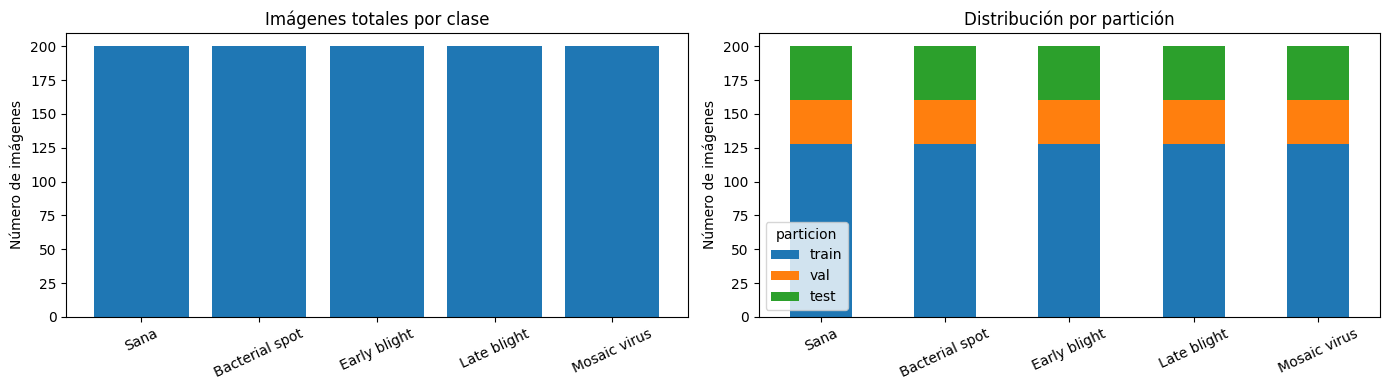

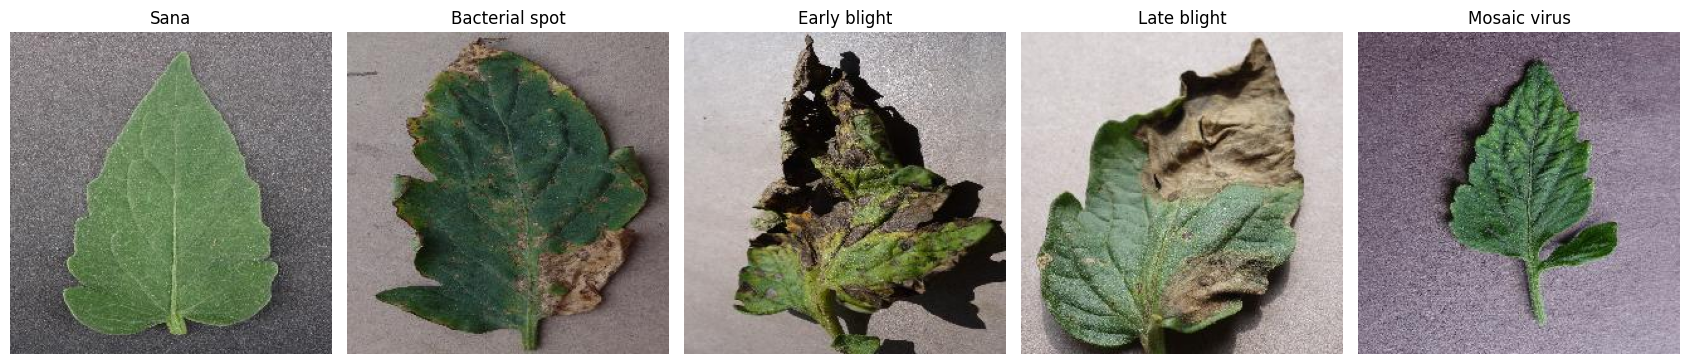

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
conteos = df.groupby('clase').size().reindex(CLASES)
axs[0].bar(NOMBRES_CORTOS, conteos.values)
axs[0].set_title('Imágenes totales por clase')
axs[0].set_ylabel('Número de imágenes')
axs[0].tick_params(axis='x', rotation=25)

part = pd.crosstab(df.clase, df.particion).reindex(CLASES).reindex(columns=['train','val','test'])
part.index = NOMBRES_CORTOS
part.plot(kind='bar', stacked=True, ax=axs[1])
axs[1].set_title('Distribución por partición')
axs[1].set_ylabel('Número de imágenes')
axs[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(RESULTADOS / 'eda_distribucion.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for i, clase in enumerate(CLASES):
    ruta = (DATOS / df.loc[df.clase == clase,'ruta_relativa'].iloc[0])
    with Image.open(ruta) as img:
        axes[i].imshow(img.convert('RGB'))
    axes[i].set_title(NOMBRES_CORTOS[i])
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(RESULTADOS / 'eda_ejemplos.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Preprocesamiento y DataLoaders
Se redimensionan las imágenes a **224 × 224** y se normalizan con los parámetros de ImageNet, coherentes con los pesos preentrenados de ResNet18. Para entrenamiento se usa aumento de datos; para el pseudo-etiquetado se crean una **vista débil** (predicción) y una **vista fuerte** (aprendizaje de consistencia). Validación y prueba **no** incluyen aumentos aleatorios.

In [7]:
NORMALIZACION = transforms.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225))
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.80,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(12),
    transforms.ToTensor(), NORMALIZACION
])
weak_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), NORMALIZACION
])
strong_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=7),
    transforms.ToTensor(), NORMALIZACION
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), NORMALIZACION
])

class HojasDataset(Dataset):
    def __init__(self, frame, transform, es_no_etiquetado=False):
        self.registros = frame.reset_index(drop=True)
        self.transform = transform
        self.es_no_etiquetado = es_no_etiquetado

    def __len__(self):
        return len(self.registros)

    def __getitem__(self, indice):
        fila = self.registros.iloc[indice]
        ruta = DATOS / fila['ruta_relativa']
        with Image.open(ruta) as imagen:
            imagen = imagen.convert('RGB')
            if self.es_no_etiquetado:
                return weak_transform(imagen), strong_transform(imagen)
            return self.transform(imagen), int(fila['label'])

def cargar_datos(frame, transform=None, sin_etiqueta=False, shuffle=False):
    dataset = HojasDataset(frame, transform, sin_etiqueta)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=='cuda'))

loader_train_25 = cargar_datos(labeled_df, train_transform, shuffle=True)
loader_train_100 = cargar_datos(train_df, train_transform, shuffle=True)
loader_unlabeled = cargar_datos(unlabeled_df, sin_etiqueta=True, shuffle=True)
loader_val = cargar_datos(val_df, eval_transform)
loader_test = cargar_datos(test_df, eval_transform)
print('Lotes supervisado 25 %:', len(loader_train_25))
print('Lotes supervisado 100 %:', len(loader_train_100))
print('Lotes no etiquetados:', len(loader_unlabeled))

Lotes supervisado 25 %: 5
Lotes supervisado 100 %: 20
Lotes no etiquetados: 15


## 7. Arquitectura, optimización y métricas
Se emplea **ResNet18 preentrenada en ImageNet**, ajustada a cinco clases. Se congela el extractor inicial y se entrenan el bloque final `layer4` y la capa clasificadora `fc`, evitando un ajuste completo costoso para una muestra pequeña.

**Métrica de selección:** F1 macro en validación (promedia el F1 de las cinco clases). También se registran accuracy, precision macro, recall macro, pérdida y matriz de confusión.

In [8]:
def construir_modelo():
    modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for param in modelo.parameters():
        param.requires_grad = False
    for param in modelo.layer4.parameters():
        param.requires_grad = True
    modelo.fc = nn.Linear(modelo.fc.in_features, len(CLASES))
    return modelo.to(DEVICE)

def crear_optimizador(modelo):
    return torch.optim.AdamW([
        {'params': modelo.layer4.parameters(), 'lr': LEARNING_RATE_LAYER4},
        {'params': modelo.fc.parameters(), 'lr': LEARNING_RATE_FC}
    ], weight_decay=WEIGHT_DECAY)

def poner_modo_entrenamiento(modelo):
    modelo.train()
    # El backbone congelado conserva estadísticas de BatchNorm de ImageNet.
    for modulo in [modelo.bn1, modelo.layer1, modelo.layer2, modelo.layer3]:
        modulo.eval()

def calcular_metricas(etiquetas_reales, predicciones):
    precision, recall, f1, _ = precision_recall_fscore_support(
        etiquetas_reales, predicciones, labels=list(range(len(CLASES))),
        average='macro', zero_division=0
    )
    return {
        'accuracy': accuracy_score(etiquetas_reales, predicciones),
        'precision_macro': precision,
        'recall_macro': recall,
        'f1_macro': f1
    }

@torch.no_grad()
def evaluar(modelo, loader):
    modelo.eval()
    verdaderas, predichas = [], []
    perdida_total, total = 0., 0
    for imagenes, etiquetas in loader:
        imagenes = imagenes.to(DEVICE, non_blocking=True)
        etiquetas = etiquetas.to(DEVICE, non_blocking=True)
        logits = modelo(imagenes)
        perdida_total += F.cross_entropy(logits, etiquetas, reduction='sum').item()
        total += len(etiquetas)
        verdaderas.extend(etiquetas.cpu().tolist())
        predichas.extend(logits.argmax(dim=1).cpu().tolist())
    metricas = calcular_metricas(verdaderas, predichas)
    metricas['loss'] = perdida_total / max(1,total)
    return metricas, np.array(verdaderas), np.array(predichas)

def guardar_checkpoint(modelo, ruta, epoca, valor_f1):
    torch.save({
        'model_state_dict': modelo.state_dict(),
        'class_names': CLASES,
        'epoch': epoca,
        'val_f1_macro': float(valor_f1),
        'seed': SEED,
    }, ruta)

def recuperar_checkpoint(modelo, ruta):
    registro = torch.load(ruta, map_location=DEVICE, weights_only=True)
    modelo.load_state_dict(registro['model_state_dict'])
    return registro

historias = {}
checkpoints = {}

## 8. Entrenamiento supervisado
Se entrenan dos modelos con **idéntica arquitectura**: uno utiliza el 25 % de las etiquetas disponibles y otro el 100 % del conjunto de entrenamiento. El mejor checkpoint se elige **solo** por F1 macro en validación. Se aplica *early stopping* para limitar el sobreajuste.

In [9]:
def entrenar_supervisado(nombre, loader, epocas=EPOCHS):
    fijar_semilla(SEED)
    modelo = construir_modelo()
    optimizador = crear_optimizador(modelo)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=epocas)
    mejor_f1, espera = -1., 0
    historial = []
    checkpoint = RESULTADOS / f'{nombre}.pth'

    for epoca in range(1, epocas + 1):
        poner_modo_entrenamiento(modelo)
        suma_loss, total = 0., 0
        for imagenes, etiquetas in loader:
            imagenes = imagenes.to(DEVICE, non_blocking=True)
            etiquetas = etiquetas.to(DEVICE, non_blocking=True)
            optimizador.zero_grad(set_to_none=True)
            logits = modelo(imagenes)
            loss = F.cross_entropy(logits, etiquetas)
            loss.backward()
            optimizador.step()
            suma_loss += loss.item() * len(etiquetas)
            total += len(etiquetas)

        scheduler.step()
        val, _, _ = evaluar(modelo, loader_val)
        fila = {
            'modelo': nombre, 'epoca': epoca, 'train_loss': suma_loss / max(1,total),
            'val_loss': val['loss'], 'val_accuracy': val['accuracy'],
            'val_f1_macro': val['f1_macro'], 'pseudo_aceptacion': np.nan
        }
        historial.append(fila)
        print(f'{nombre} | época {epoca:02d}/{epocas} | '
              f'train_loss={fila["train_loss"]:.4f} | val_F1={val["f1_macro"]:.4f}')
        if val['f1_macro'] > mejor_f1 + 1e-6:
            mejor_f1, espera = val['f1_macro'], 0
            guardar_checkpoint(modelo, checkpoint, epoca, mejor_f1)
        else:
            espera += 1
            if espera >= PATIENCE:
                print('Early stopping:', nombre)
                break

    recuperar_checkpoint(modelo, checkpoint)
    historias[nombre] = pd.DataFrame(historial)
    checkpoints[nombre] = str(checkpoint)
    metricas_val, _, _ = evaluar(modelo, loader_val)
    print(f'>> Mejor {nombre} | val_F1_macro = {metricas_val["f1_macro"]:.4f}\n')
    del modelo
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metricas_val

metricas_val_25 = entrenar_supervisado('supervisado_25', loader_train_25)
metricas_val_100 = entrenar_supervisado('supervisado_100', loader_train_100)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 213MB/s]


supervisado_25 | época 01/12 | train_loss=1.4635 | val_F1=0.6499
supervisado_25 | época 02/12 | train_loss=0.7251 | val_F1=0.8118
supervisado_25 | época 03/12 | train_loss=0.3757 | val_F1=0.7819
supervisado_25 | época 04/12 | train_loss=0.2770 | val_F1=0.8984
supervisado_25 | época 05/12 | train_loss=0.1519 | val_F1=0.9112
supervisado_25 | época 06/12 | train_loss=0.1348 | val_F1=0.9177
supervisado_25 | época 07/12 | train_loss=0.1026 | val_F1=0.9238
supervisado_25 | época 08/12 | train_loss=0.0834 | val_F1=0.9238
supervisado_25 | época 09/12 | train_loss=0.0886 | val_F1=0.9238
supervisado_25 | época 10/12 | train_loss=0.0777 | val_F1=0.9238
supervisado_25 | época 11/12 | train_loss=0.0717 | val_F1=0.9301
supervisado_25 | época 12/12 | train_loss=0.0573 | val_F1=0.9301
>> Mejor supervisado_25 | val_F1_macro = 0.9301

supervisado_100 | época 01/12 | train_loss=0.8245 | val_F1=0.8571
supervisado_100 | época 02/12 | train_loss=0.2223 | val_F1=0.9307
supervisado_100 | época 03/12 | train_l

## 9. Aprendizaje semi-supervisado con pseudo-etiquetado y consistencia
Este experimento emplea las **mismas imágenes etiquetadas (25 %)** y usa el resto del conjunto de entrenamiento sin consultar sus etiquetas. Durante las primeras `EPOCHS_WARMUP` épocas entrena únicamente con etiquetas; después usa predicciones de una vista débil cuando su confianza supera `UMBRAL_CONFIANZA` como pseudo-etiquetas para una versión fuertemente aumentada.

**Pérdida:** `L = L_supervisada + λ × L_no_etiquetada`. Este método es una **variante simplificada inspirada en FixMatch**; no se afirma que sea una reproducción exacta de su implementación oficial. Las etiquetas verdaderas del subconjunto no etiquetado **nunca se usan** para entrenar o decidir si aceptar una pseudo-etiqueta.

In [10]:
def entrenar_semi_supervisado(nombre='semi_supervisado_25', epocas=EPOCHS):
    fijar_semilla(SEED)
    modelo = construir_modelo()
    optimizador = crear_optimizador(modelo)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=epocas)
    mejor_f1, espera = -1., 0
    historial = []
    checkpoint = RESULTADOS / f'{nombre}.pth'

    for epoca in range(1, epocas + 1):
        poner_modo_entrenamiento(modelo)
        suma_loss, total_l, aceptadas, observadas = 0., 0, 0, 0
        iterador_u = iter(loader_unlabeled)

        for imagenes_l, etiquetas_l in loader_train_25:
            imagenes_l = imagenes_l.to(DEVICE, non_blocking=True)
            etiquetas_l = etiquetas_l.to(DEVICE, non_blocking=True)
            optimizador.zero_grad(set_to_none=True)
            logits_l = modelo(imagenes_l)
            loss_s = F.cross_entropy(logits_l, etiquetas_l)
            loss = loss_s

            if epoca > EPOCHS_WARMUP:
                try:
                    imagenes_w, imagenes_f = next(iterador_u)
                except StopIteration:
                    iterador_u = iter(loader_unlabeled)
                    imagenes_w, imagenes_f = next(iterador_u)
                imagenes_w = imagenes_w.to(DEVICE, non_blocking=True)
                imagenes_f = imagenes_f.to(DEVICE, non_blocking=True)

                # Solo una predicción del modelo, no se accede a las etiquetas reales.
                with torch.no_grad():
                    probabilidades = F.softmax(modelo(imagenes_w), dim=1)
                    confianza, pseudo = probabilidades.max(dim=1)
                    mascara = confianza.ge(UMBRAL_CONFIANZA).float()

                logits_fuertes = modelo(imagenes_f)
                perdidas_u = F.cross_entropy(logits_fuertes, pseudo, reduction='none')
                # Normalización por lote: cuando no se acepta ninguna, L_u = 0.
                loss_u = (perdidas_u * mascara).mean()
                loss = loss_s + PESO_NO_ETIQUETADO * loss_u
                aceptadas += int(mascara.sum().item())
                observadas += len(mascara)

            loss.backward()
            optimizador.step()
            suma_loss += loss.item() * len(etiquetas_l)
            total_l += len(etiquetas_l)

        scheduler.step()
        val, _, _ = evaluar(modelo, loader_val)
        tasa_aceptacion = aceptadas / observadas if observadas else 0.0
        fila = {
            'modelo': nombre, 'epoca': epoca, 'train_loss': suma_loss/max(1,total_l),
            'val_loss': val['loss'], 'val_accuracy': val['accuracy'],
            'val_f1_macro': val['f1_macro'], 'pseudo_aceptacion': tasa_aceptacion
        }
        historial.append(fila)
        print(f'{nombre} | época {epoca:02d}/{epocas} | '
              f'train_loss={fila["train_loss"]:.4f} | val_F1={val["f1_macro"]:.4f} | '
              f'pseudo_aceptadas={100*tasa_aceptacion:.1f}%')
        if val['f1_macro'] > mejor_f1 + 1e-6:
            mejor_f1, espera = val['f1_macro'], 0
            guardar_checkpoint(modelo, checkpoint, epoca, mejor_f1)
        else:
            espera += 1
            if espera >= PATIENCE:
                print('Early stopping:', nombre)
                break

    recuperar_checkpoint(modelo, checkpoint)
    historias[nombre] = pd.DataFrame(historial)
    checkpoints[nombre] = str(checkpoint)
    metricas_val, _, _ = evaluar(modelo, loader_val)
    print(f'>> Mejor {nombre} | val_F1_macro = {metricas_val["f1_macro"]:.4f}\n')
    del modelo
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metricas_val

metricas_val_semi = entrenar_semi_supervisado()

semi_supervisado_25 | época 01/12 | train_loss=1.4170 | val_F1=0.7119 | pseudo_aceptadas=0.0%
semi_supervisado_25 | época 02/12 | train_loss=0.6831 | val_F1=0.8560 | pseudo_aceptadas=0.0%
semi_supervisado_25 | época 03/12 | train_loss=0.3350 | val_F1=0.8804 | pseudo_aceptadas=0.0%
semi_supervisado_25 | época 04/12 | train_loss=0.2488 | val_F1=0.9242 | pseudo_aceptadas=43.1%
semi_supervisado_25 | época 05/12 | train_loss=0.1779 | val_F1=0.9368 | pseudo_aceptadas=53.8%
semi_supervisado_25 | época 06/12 | train_loss=0.1926 | val_F1=0.9430 | pseudo_aceptadas=63.1%
semi_supervisado_25 | época 07/12 | train_loss=0.1518 | val_F1=0.9430 | pseudo_aceptadas=70.0%
semi_supervisado_25 | época 08/12 | train_loss=0.1032 | val_F1=0.9430 | pseudo_aceptadas=70.0%
semi_supervisado_25 | época 09/12 | train_loss=0.0931 | val_F1=0.9430 | pseudo_aceptadas=70.0%
semi_supervisado_25 | época 10/12 | train_loss=0.0915 | val_F1=0.9496 | pseudo_aceptadas=68.8%
semi_supervisado_25 | época 11/12 | train_loss=0.1015

## 10. Curvas y comparación sobre validación
Estas gráficas permiten observar si aparece sobreajuste, si el pseudo-etiquetado acepta suficientes muestras y si el modelo semi-supervisado aporta alguna mejora inicial. **No se utilizará el conjunto de prueba para ajustar parámetros.**

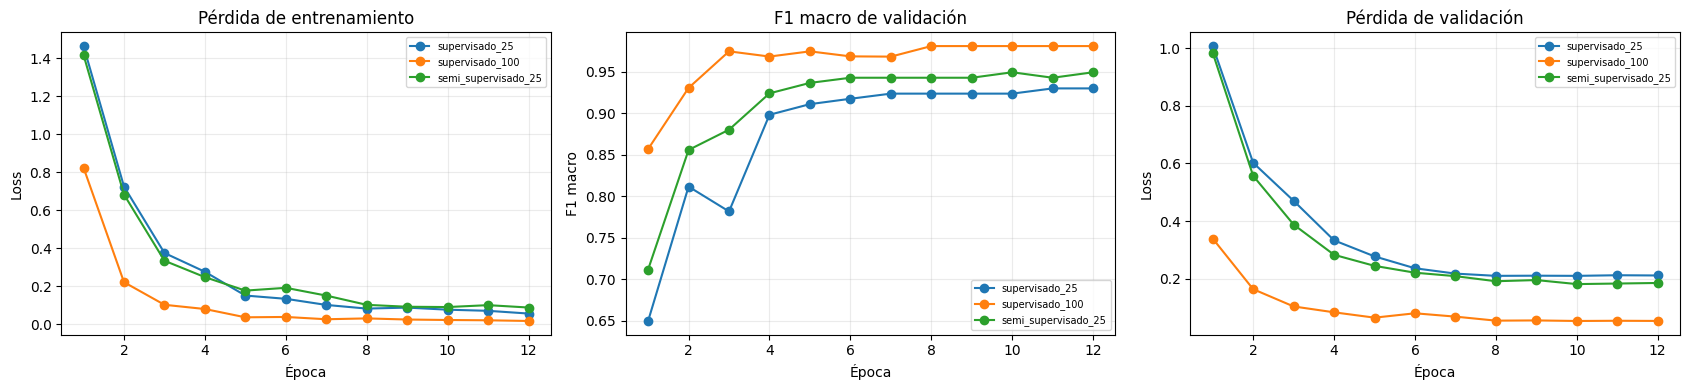

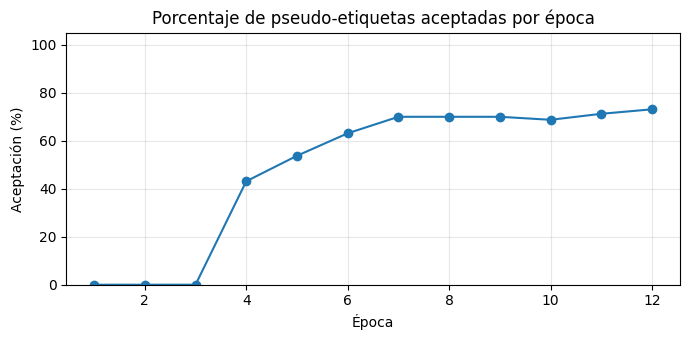

,modelo,accuracy,precision_macro,recall_macro,f1_macro,loss
0,supervisado_25,0.9312,0.9360,0.9312,0.9301,0.2125
1,semi_supervisado_25,0.9500,0.9501,0.9500,0.9496,0.1818
2,supervisado_100,0.9812,0.9816,0.9812,0.9811,0.0551


In [11]:
historial_total = pd.concat(historias.values(), ignore_index=True)
historial_total.to_csv(RESULTADOS / 'historial_entrenamiento.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for nombre, hist in historias.items():
    axes[0].plot(hist['epoca'], hist['train_loss'], marker='o', label=nombre)
    axes[1].plot(hist['epoca'], hist['val_f1_macro'], marker='o', label=nombre)
    axes[2].plot(hist['epoca'], hist['val_loss'], marker='o', label=nombre)
axes[0].set_title('Pérdida de entrenamiento')
axes[1].set_title('F1 macro de validación')
axes[2].set_title('Pérdida de validación')
for ax in axes:
    ax.set_xlabel('Época')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
axes[0].set_ylabel('Loss')
axes[1].set_ylabel('F1 macro')
axes[2].set_ylabel('Loss')
plt.tight_layout()
plt.savefig(RESULTADOS / 'curvas_entrenamiento.png', dpi=180, bbox_inches='tight')
plt.show()

semi_hist = historias['semi_supervisado_25']
plt.figure(figsize=(7, 3.5))
plt.plot(semi_hist['epoca'], 100*semi_hist['pseudo_aceptacion'], marker='o')
plt.title('Porcentaje de pseudo-etiquetas aceptadas por época')
plt.xlabel('Época'); plt.ylabel('Aceptación (%)'); plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTADOS / 'pseudo_etiquetas_aceptadas.png', dpi=180, bbox_inches='tight')
plt.show()

val_filas = []
for nombre, m in [('supervisado_25', metricas_val_25),
                  ('semi_supervisado_25', metricas_val_semi),
                  ('supervisado_100', metricas_val_100)]:
    val_filas.append({'modelo':nombre, **m})
resumen_val = pd.DataFrame(val_filas)
display(resumen_val.round(4))
resumen_val.to_csv(RESULTADOS / 'metricas_validacion.csv', index=False)

## 11. Evaluación final en el conjunto de prueba
**Ejecutar después de completar y revisar los entrenamientos.** Se carga el mejor checkpoint de cada modelo, elegido por validación, y **solo aquí** se accede a la prueba. Se generan métricas macro, reporte por clase, matriz de confusión y comparación en F1 macro.

Prueba | supervisado_25 | accuracy=0.9350 | F1 macro=0.9345
Prueba | semi_supervisado_25 | accuracy=0.9550 | F1 macro=0.9551
Prueba | supervisado_100 | accuracy=0.9800 | F1 macro=0.9801


,modelo,epoca_mejor,accuracy,precision_macro,recall_macro,f1_macro,loss
0,supervisado_25,11,0.935,0.9372,0.935,0.9345,0.2280
1,semi_supervisado_25,10,0.955,0.9555,0.955,0.9551,0.1980
2,supervisado_100,8,0.980,0.9805,0.980,0.9801,0.0581


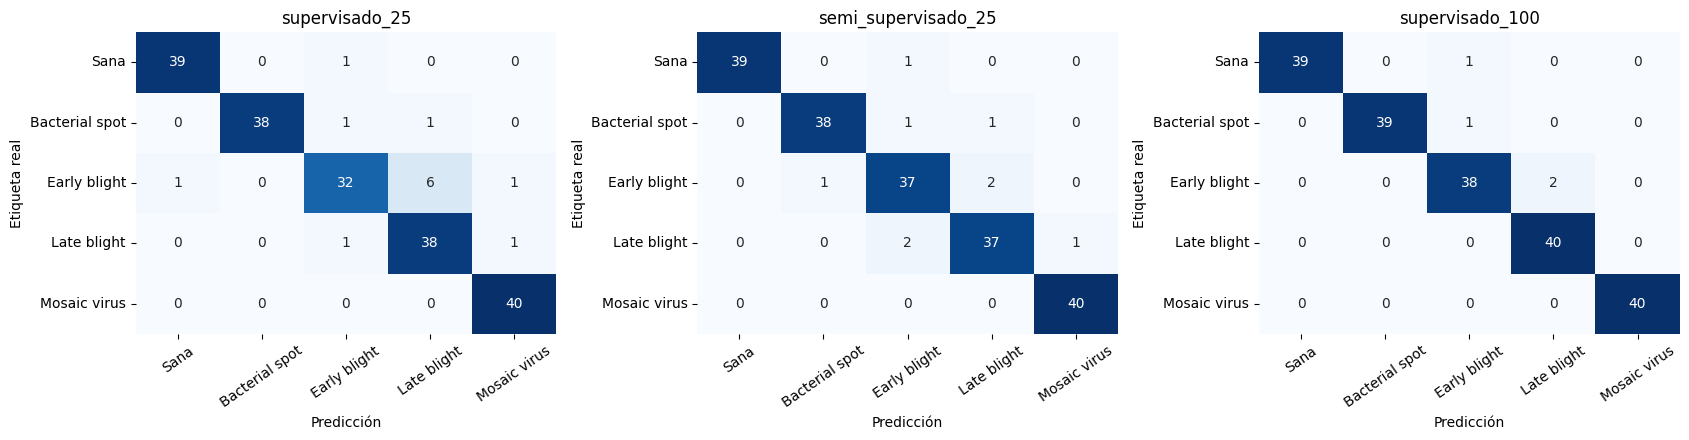

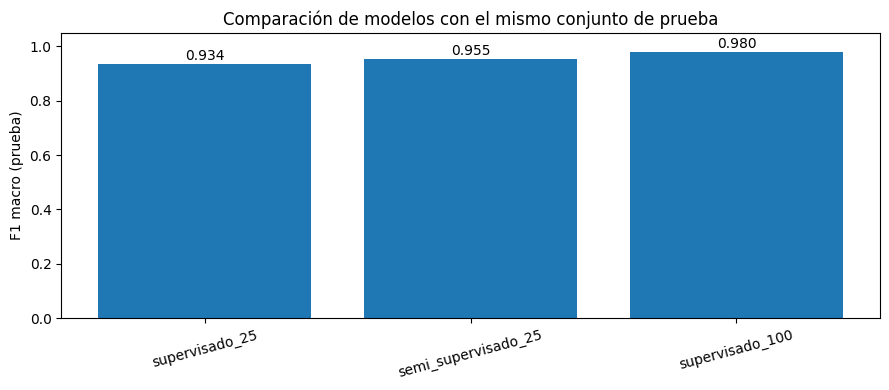

Diferencia F1 macro (semi 25 % - supervisado 25 %) = +0.0206
Interpretación: mejora


In [12]:
resultados_test = []
matrices = {}
reportes_por_clase = []
orden_modelos = ['supervisado_25', 'semi_supervisado_25', 'supervisado_100']

for nombre in orden_modelos:
    modelo = construir_modelo()
    info = recuperar_checkpoint(modelo, checkpoints[nombre])
    metricas, y_true, y_pred = evaluar(modelo, loader_test)
    resultados_test.append({
        'modelo': nombre, 'epoca_mejor': info['epoch'], **metricas
    })
    matrices[nombre] = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASES))))
    reporte = classification_report(
        y_true, y_pred, labels=list(range(len(CLASES))),
        target_names=NOMBRES_CORTOS, zero_division=0, output_dict=True
    )
    for clase in NOMBRES_CORTOS:
        reportes_por_clase.append({
            'modelo': nombre, 'clase': clase,
            'precision': reporte[clase]['precision'],
            'recall': reporte[clase]['recall'],
            'f1': reporte[clase]['f1-score'],
            'soporte': reporte[clase]['support']
        })
    print(f'Prueba | {nombre} | accuracy={metricas["accuracy"]:.4f} | F1 macro={metricas["f1_macro"]:.4f}')
    del modelo
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

resumen_test = pd.DataFrame(resultados_test)
display(resumen_test.round(4))
resumen_test.to_csv(RESULTADOS / 'metricas_test.csv', index=False)
pd.DataFrame(reportes_por_clase).to_csv(RESULTADOS / 'metricas_por_clase.csv', index=False)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, nombre in zip(axs, orden_modelos):
    sns.heatmap(matrices[nombre], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=NOMBRES_CORTOS, yticklabels=NOMBRES_CORTOS, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Etiqueta real')
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.savefig(RESULTADOS / 'matrices_confusion_test.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(resumen_test['modelo'], resumen_test['f1_macro'])
plt.ylabel('F1 macro (prueba)')
plt.title('Comparación de modelos con el mismo conjunto de prueba')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
for x, value in enumerate(resumen_test['f1_macro']):
    plt.text(x, value + 0.015, f'{value:.3f}', ha='center')
plt.tight_layout()
plt.savefig(RESULTADOS / 'comparacion_f1_test.png', dpi=180, bbox_inches='tight')
plt.show()

delta_f1 = (resumen_test.loc[resumen_test.modelo=='semi_supervisado_25','f1_macro'].iloc[0]
            - resumen_test.loc[resumen_test.modelo=='supervisado_25','f1_macro'].iloc[0])
print(f'Diferencia F1 macro (semi 25 % - supervisado 25 %) = {delta_f1:+.4f}')
print('Interpretación: mejora' if delta_f1 > 0 else
      ('Interpretación: empate' if delta_f1 == 0 else 'Interpretación: no mejora'))

## 12. Reproducibilidad y exportación de resultados
Se guarda la configuración experimental, las versiones de bibliotecas, las particiones, checkpoints y figuras. **No incluyas `data.zip` ni las imágenes completas en GitHub.** El README del repositorio debe enlazar el dataset e indicar GPU, instalación, orden de ejecución y dónde encontrar los resultados.

**Alcance:** los resultados son **preliminares** y se estiman sobre un subconjunto de 1.000 fotografías RGB de un entorno controlado. No demuestran generalización a imágenes tomadas en cultivos reales. La comparación de una sola semilla no permite evaluar variabilidad estadística; las repeticiones y escenarios 10/50 % quedan propuestos para la Entrega 3.

In [13]:
configuracion = {
    'proyecto': 'IA2 Entrega 2 — PlantVillage semi-supervisado',
    'dataset': DATASET_ID, 'configuracion_dataset': 'color RGB',
    'fuente_splits': 'splits/color_train.txt y splits/color_test.txt',
    'seed': SEED, 'clases': CLASES,
    'imagenes_train_oficial_por_clase': TRAIN_POR_CLASE,
    'imagenes_test_oficial_por_clase': TEST_POR_CLASE,
    'fraccion_val': FRACCION_VALIDACION,
    'fraccion_etiquetas_objetivo': FRACCION_ETIQUETAS,
    'fraccion_etiquetas_observada': len(labeled_df)/len(train_df),
    'n_train': len(train_df), 'n_val': len(val_df), 'n_test': len(test_df),
    'n_etiquetado': len(labeled_df), 'n_no_etiquetado': len(unlabeled_df),
    'arquitectura': 'ResNet18 ImageNet, train layer4 + fc',
    'imagen_size': IMG_SIZE, 'batch_size': BATCH_SIZE,
    'epochs_maximas': EPOCHS, 'warmup_epochs': EPOCHS_WARMUP,
    'patience': PATIENCE, 'lr_fc': LEARNING_RATE_FC,
    'lr_layer4': LEARNING_RATE_LAYER4, 'weight_decay': WEIGHT_DECAY,
    'umbral_pseudoetiqueta': UMBRAL_CONFIANZA,
    'lambda_u': PESO_NO_ETIQUETADO,
    'hardware': str(DEVICE),
    'version_python': platform.python_version(),
    'version_torch': torch.__version__,
    'version_torchvision': __import__('torchvision').__version__,
    'version_numpy': np.__version__, 'version_pandas': pd.__version__,
    'nota': 'Subconjunto balanceado. Resultados test calculados una sola vez al final.'
}
with open(RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

print('Archivos guardados en:', RESULTADOS)
for ruta in sorted(RESULTADOS.iterdir()):
    print(' -', ruta.name)

# Archivo opcional para descargar los resultados desde Colab.
ARCHIVO_ZIP = shutil.make_archive(str(RESULTADOS.parent / 'resultados_parte2'), 'zip', root_dir=RESULTADOS)
print('\nZIP de resultados:', ARCHIVO_ZIP)
print('Si quieres conservar el ZIP, búscalo en la barra lateral Archivos de Colab,')
print('o activa GUARDAR_EN_DRIVE=True al inicio y vuelve a ejecutar el notebook.')

Archivos guardados en: /content/IA2_Proyecto_Parte2/resultados
 - comparacion_f1_test.png
 - configuracion.json
 - curvas_entrenamiento.png
 - eda_distribucion.png
 - eda_ejemplos.png
 - historial_entrenamiento.csv
 - labeled_25.csv
 - matrices_confusion_test.png
 - metricas_por_clase.csv
 - metricas_test.csv
 - metricas_validacion.csv
 - particiones.csv
 - pseudo_etiquetas_aceptadas.png
 - semi_supervisado_25.pth
 - supervisado_100.pth
 - supervisado_25.pth
 - unlabeled_75.csv

ZIP de resultados: /content/IA2_Proyecto_Parte2/resultados_parte2.zip
Si quieres conservar el ZIP, búscalo en la barra lateral Archivos de Colab,
o activa GUARDAR_EN_DRIVE=True al inicio y vuelve a ejecutar el notebook.


In [14]:
from google.colab import files

files.download('/content/IA2_Proyecto_Parte2/resultados_parte2.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Referencias fundamentales
- Mohanty, S. P., Hughes, D. P., & Salathé, M. (2016). *Using deep learning for image-based plant disease detection*. Frontiers in Plant Science, 7, 1419. https://doi.org/10.3389/fpls.2016.01419
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep residual learning for image recognition*. CVPR.
- Sohn, K. et al. (2020). *FixMatch: Simplifying semi-supervised learning with consistency and confidence*. NeurIPS.
- PlantVillage: https://huggingface.co/datasets/mohanty/PlantVillage

.

.

.

.

.

.

.

.

.

.

.

.

.

.

.